# E1 — Training Baseline: Urban Street Tree Classification

**Course:** Neural Networks for Computer Vision (HAMK, 5 op)
**Teacher:** Tommi Lahti
**Dataset:** Urban Street Tree Classification (Kaggle, `erickendric`)
**Task:** 23-class urban street-tree species image classification
**Input:** Clean dataset at `./data/clean_tree` (produced by `Dan_preprocessing_local.ipynb`)
**Environment:** Local laptop (Windows / macOS / Linux)
**Outputs:** `./outputs/dan/training_baseline/` (+ shared registry `./outputs/dan/experiment_results.csv`)

---

## Local directory structure

This notebook expects the following folder structure in your current working directory:

```text
project_root/
├── Dan_preprocessing_local.ipynb
├── Dan_E1_training_baseline_local.ipynb    (this notebook)
├── Dan_E2_training_local.ipynb             (E2, ResNet-50)
├── Dan_E2_training_local_resnet34.ipynb    (E2 variant, ResNet-34)
├── Dan_E3_training_improvement_local.ipynb
├── data/
│   ├── tree/                     (raw downloaded dataset)
│   └── clean_tree/               (generated by Dan_preprocessing_local.ipynb)
│       ├── train/
│       ├── val/
│       └── test/
└── outputs/
    └── dan/
        ├── preprocessing/              (artifacts of Dan_preprocessing_local.ipynb)
        ├── experiment_results.csv      (shared cross-experiment registry)
        ├── training_baseline/          (E1 artifacts, generated by this notebook)
        └── training/                   (E2 and E3 artifacts)
```

---

## Experiment naming convention

This project uses a fixed experiment naming convention across all notebooks:

| ID | Name | Notebook | Purpose |
|---|---|---|---|
| **E1** | ResNet-18 baseline | `Dan_E1_training_baseline_local.ipynb` (this file) | Establish reproducible reference |
| **E2 (ResNet-50)** | Architecture comparison | `Dan_E2_training_local.ipynb` | ResNet-18 vs ResNet-50 |
| **E2 (ResNet-34)** | Architecture comparison variant | `Dan_E2_training_local_resnet34.ipynb` | ResNet-18 vs ResNet-34 |
| **E3** | Improvement experiment | `Dan_E3_training_improvement_local.ipynb` | Evidence-driven change from error analysis; base architecture selected from the E1/E2 registry rows (`resnet18` / `resnet34` / `resnet50`) |
| **Final** | Final evaluation | Section at end of E3 | Freeze models → test once |

This convention is maintained in every notebook, every results table, and every figure title so the Word report is easy to follow.

**Downstream dependencies on E1:**

- Both E2 variants load `outputs/dan/training_baseline/resnet18_E1_topk.json` to build the cross-model Top-k overlay plot and separation-point analysis.
- E3 reads the shared registry and selects the best E1/E2 row by validation Macro-F1 as its base model. E1 therefore remains the reference even when deeper architectures are tested.

---

## Clean dataset (from preprocessing)

| Split | Images |
|---|---:|
| Train | 3,850 |
| Validation | 401 |
| Test | 405 |
| **Total** | **4,656** |

23 tree species. Training imbalance ratio: 3.60× (largest / smallest class).

---

## Test-set policy (applies to ALL experiments)

```text
TRAIN
  ↓
VALIDATION  ← choose architecture / augmentation / hyperparameters
  ↓
FREEZE FINAL MODELS
  ↓
TEST ONCE   ← report only; never use to make decisions
```

**The test set is never used to decide which model, augmentation, loss, or epoch is better.** Those decisions are made exclusively on the validation set. The test set is evaluated exactly once per frozen model at the very end.

---

## What E1 establishes

- **Model:** ResNet-18 pretrained on ImageNet
- **Strategy:** transfer learning (head warmup → full fine-tuning)
- **Loss:** CrossEntropyLoss (unweighted)
- **Optimizer:** AdamW
- **Scheduler:** ReduceLROnPlateau
- **Augmentation:** mild, domain-aware
- **Primary validation metric:** Macro-F1
- **Teacher-required metrics:** Accuracy, Precision, Recall, F1 (macro-averaged)
- **Additional metrics:** Balanced accuracy, Weighted-F1, Top-k (k = 1…10)
- **Checkpoint selection:** validation Macro-F1 → accuracy → loss
- **Shared artifacts for later experiments:** registry row (`E1 / resnet18`) and `resnet18_E1_topk.json`

The objective is **not** maximum accuracy. The objective is a **stable, reproducible reference** for E2 and E3.

## Connection to course topics

This notebook directly applies concepts from Topics 1–4 of the course:

```text
Topic 1: ANN Basics & Gradient Descent
  → loss function, learning rate, weight updates

Topic 2: Tensors, Autograd, Optimizers, DataLoader
  → Image → Tensor → DataLoader → forward pass → backward() → AdamW step

Topic 3: Classification with Neural Networks
  → logits → softmax → CrossEntropyLoss → predictions → metrics

Topic 4: CNNs and Transfer Learning
  → ResNet-18 → pretrained backbone → head replacement → fine-tuning
```

The complete data-to-prediction pipeline used in this notebook:

```text
Image (.jpg on disk)
  ↓  PIL.Image.open + RGB conversion
PIL Image (RGB)
  ↓  transforms (crop, flip, normalize)
Tensor (3 × 224 × 224)
  ↓  DataLoader (batching, shuffling)
Batch Tensor (B × 3 × 224 × 224)
  ↓  model.forward()
Logits (B × 23)
  ↓  CrossEntropyLoss(logits, labels)
Scalar Loss
  ↓  loss.backward()
Gradients (∂L/∂w for every parameter)
  ↓  optimizer.step()
Updated Weights
  ↓  repeat for each epoch
Validation → Metrics → Checkpoint
  ↓  after all experiments
Test Once → Final Report
```

## 1. Why transfer learning?

The clean dataset contains ~4,650 images across 23 classes. This is small for training a deep CNN from scratch.

ImageNet-pretrained models already contain useful low- and mid-level visual features (edges, textures, shapes). Transfer learning provides a practical starting point.

The PyTorch transfer learning tutorial demonstrates both:
1. using a pretrained CNN as a fixed feature extractor, and
2. fine-tuning a pretrained CNN on the new task.

This notebook combines both: head warmup (feature extraction) → full fine-tuning.

### Alternatives

| Approach | Why not baseline |
|---|---|
| Train from scratch | Too few images; no pretrained features |
| Linear probing only | May leave task-specific features under-adapted |
| Full fine-tuning from epoch 1 | Random head sends destructive gradients to pretrained backbone |

### Resources

- Yosinski et al. (2014), *How transferable are features in deep neural networks?*, NeurIPS. https://arxiv.org/abs/1411.1792
- He et al. (2016), *Deep Residual Learning for Image Recognition*, CVPR. https://arxiv.org/abs/1512.03385
- PyTorch Transfer Learning Tutorial. https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

## 2. Why ResNet-18 as the baseline?

The project requires **2 different sized ResNet architectures**. ResNet-18 is the smaller one.

| Property | ResNet-18 | ResNet-50 |
|---|---:|---:|
| Depth | 18 layers | 50 layers |
| Parameters | ~11.7 M | ~25.6 M |
| Block type | BasicBlock | Bottleneck |
| Role in project | E1 baseline | E2 comparison |

ResNet-18 is chosen first because:
1. Fast to train on local hardware (CUDA GPU / Apple MPS / CPU)
2. Lower capacity → useful for testing whether depth actually helps
3. Well-established and reproducible

E2 will train ResNet-50 under **identical conditions** (same data, transforms, loss, optimizer, seed) so that architecture capacity is the only changing variable.

### Resources

- He et al. (2016), ResNet. https://arxiv.org/abs/1512.03385
- Torchvision ResNet models. https://pytorch.org/vision/stable/models.html

In [1]:
# --- Imports needed if running this cell standalone ---
import torch
from pathlib import Path

def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    elif torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

DEVICE = get_device()

# --- Local directory configuration ---
BASE_DIR = Path(".").resolve()
DATA_DIR = BASE_DIR / "data"

# Shared folder for Dan's cross-experiment artifacts
DAN_OUTPUTS_DIR = BASE_DIR / "outputs" / "dan"
OUTPUT_DIR = DAN_OUTPUTS_DIR / "training_baseline"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Clean dataset produced locally by Dan_preprocessing.ipynb
CLEAN_ROOT = DATA_DIR / "clean_tree"
TRAIN_DIR = CLEAN_ROOT / "train"
VAL_DIR = CLEAN_ROOT / "val"
TEST_DIR = CLEAN_ROOT / "test"

EXPECTED_NUM_CLASSES = 23
BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 20
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
LR_FACTOR = 0.5
LR_PATIENCE = 3
EARLY_STOPPING_PATIENCE = 5

USE_AMP = DEVICE.type == "cuda"
MODEL_NAME = "resnet18"
EXPERIMENT_ID = "E1"

CKPT_PATH = OUTPUT_DIR / f"best_{MODEL_NAME}_{EXPERIMENT_ID}.pth"
RESULTS_PATH = DAN_OUTPUTS_DIR / "experiment_results.csv"
CONFIG_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_config.json"
TOPK_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_topk.json"

assert TRAIN_DIR.exists(), f"Missing {TRAIN_DIR}. Run Dan_preprocessing_local.ipynb first."
assert VAL_DIR.exists(), f"Missing {VAL_DIR}."
assert TEST_DIR.exists(), f"Missing {TEST_DIR}."

print("Experiment:", EXPERIMENT_ID)
print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print("Train dir:", TRAIN_DIR)
print("Val dir  :", VAL_DIR)
print("Test dir :", TEST_DIR)
print("Outputs  :", OUTPUT_DIR)
print("Registry :", RESULTS_PATH)

Experiment: E1
Model: resnet18
Device: mps
Train dir: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/train
Val dir  : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/val
Test dir : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/test
Outputs  : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training_baseline
Registry : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/experiment_results.csv


In [2]:
import os, json, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score,
)

def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    elif torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

DEVICE = get_device()
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)

Device: mps


## 3. Imports, reproducibility, and device

A fixed seed reduces unnecessary variation between runs. Full GPU determinism is not guaranteed.

**Note:** The kernel metadata in this file is informational only. The actual Python version is whatever your local environment / project venv provides when you run the notebook.


In [3]:
import platform
import subprocess
import os
import torch
from pathlib import Path

def sysctl_value(key):
    """Read a macOS sysctl value."""
    try:
        result = subprocess.run(
            ["sysctl", "-n", key],
            capture_output=True,
            text=True,
            check=True
        )
        return result.stdout.strip()
    except Exception:
        return "UNKNOWN"


# ============================================================
# E1 HARDWARE / PYTORCH ENVIRONMENT
# ============================================================

print("=" * 70)
print("E1 HARDWARE / PYTORCH ENVIRONMENT")
print("=" * 70)

# ---------- System ----------
print(f"Operating system : {platform.system()}")
print(f"OS version       : {platform.mac_ver()[0]}")
print(f"Architecture     : {platform.machine()}")
print(f"CPU              : {sysctl_value('machdep.cpu.brand_string')}")
print(f"CPU cores        : {os.cpu_count()}")

# ---------- Mac hardware ----------
model = sysctl_value("hw.model")
physical_memory = sysctl_value("hw.memsize")

try:
    memory_gb = int(physical_memory) / (1024 ** 3)
    memory_display = f"{memory_gb:.0f} GB"
except Exception:
    memory_display = "UNKNOWN"

print(f"Mac model        : {model}")
print(f"Memory           : {memory_display}")

# ---------- PyTorch ----------
print(f"PyTorch version  : {torch.__version__}")

# ---------- Device ----------
if torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple Silicon GPU"
    backend = "mps"
    print(f"Device           : {device}")
    print(f"Device name      : {device_name}")
    print(f"GPU Backend      : {backend}")
else:
    device = torch.device("cpu")
    print(f"Device           : {device}")
    print("GPU Backend      : unavailable")

# ---------- Training configuration ----------
num_workers = 8
pin_memory = False
amp_enabled = False

print(f"DataLoader workers: {num_workers}")
print(f"Pin memory       : {pin_memory}")
print(f"AMP              : {amp_enabled}")

# ---------- MPS status ----------
if torch.backends.mps.is_available():
    print()
    print("✓ Apple Silicon MPS acceleration ENABLED")
    print("✓ GPU computation will use the Apple GPU")
    print("✓ Unified memory is shared between CPU and GPU")
else:
    print()
    print("⚠ MPS acceleration NOT AVAILABLE")

print("=" * 70)

E1 HARDWARE / PYTORCH ENVIRONMENT
Operating system : Darwin
OS version       : 26.3
Architecture     : arm64
CPU              : Apple M1 Pro
CPU cores        : 10
Mac model        : MacBookPro18,3
Memory           : 32 GB
PyTorch version  : 2.14.1
Device           : mps
Device name      : Apple Silicon GPU
GPU Backend      : mps
DataLoader workers: 8
Pin memory       : False
AMP              : False

✓ Apple Silicon MPS acceleration ENABLED
✓ GPU computation will use the Apple GPU
✓ Unified memory is shared between CPU and GPU


In [12]:
import torch
import numpy as np
import random

# =========================== REPRODUCIBILITY ===========================
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# =========================== CONFIGURATION ===========================
# These are the baseline hyperparameters outlined in your markdown table
BATCH_SIZE = 32
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 20
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
LR_FACTOR = 0.5
LR_PATIENCE = 3

## 4. Configuration

These are **baseline hyperparameters, not optimized values**. They remain fixed for E1.

| Parameter | Value | Rationale |
|---|---:|---|
| Batch size | 32 | Practical default for 224×224 CNN |
| Head epochs | 3 | Short classifier warmup |
| Fine-tune epochs | 20 | Sufficient initial budget |
| Head LR | 1e-3 | New head can use larger LR |
| Backbone LR | 1e-4 | Smaller update for pretrained weights |
| Weight decay | 1e-4 | Regularization (Topic 2: Weight Decay) |
| LR factor | 0.5 | Gradual reduction |
| LR patience | 3 | Avoid reacting to one noisy epoch |
| Early stopping patience | 5 | Limit overfitting |

### Why AdamW?

AdamW decouples weight decay from the adaptive gradient update. This was shown to improve generalization compared to Adam's coupled formulation.

This connects to **Topic 2 (Optimizers)** and **Topic 1 (Gradient Descent)**: the optimizer controls how gradients become weight updates, and the learning rate controls the step size.

### Resources
- Loshchilov & Hutter (2019), *Decoupled Weight Decay Regularization*, ICLR. https://arxiv.org/abs/1711.05101
- Prechelt (1998), *Early Stopping — But When?*

In [13]:
# --- Local directory configuration ---
BASE_DIR = Path(".").resolve()
DATA_DIR = BASE_DIR / "data"

# Shared folder for Dan's cross-experiment artifacts
DAN_OUTPUTS_DIR = BASE_DIR / "outputs" / "dan"
# This notebook (E1) writes all of its artifacts here
OUTPUT_DIR = DAN_OUTPUTS_DIR / "training_baseline"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Clean dataset produced locally by Dan_preprocessing.ipynb
CLEAN_ROOT = DATA_DIR / "clean_tree"
TRAIN_DIR = CLEAN_ROOT / "train"
VAL_DIR = CLEAN_ROOT / "val"
TEST_DIR = CLEAN_ROOT / "test"

EXPECTED_NUM_CLASSES = 23
BATCH_SIZE = 32
# Windows often struggles with multiprocessing in Jupyter/DataLoader, so we force 0 if on Windows
NUM_WORKERS = 0 
PIN_MEMORY = torch.cuda.is_available()

HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 20
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
LR_FACTOR = 0.5
LR_PATIENCE = 3
EARLY_STOPPING_PATIENCE = 5

USE_AMP = DEVICE.type == "cuda"
MODEL_NAME = "resnet18"
EXPERIMENT_ID = "E1"

CKPT_PATH = OUTPUT_DIR / f"best_{MODEL_NAME}_{EXPERIMENT_ID}.pth"
RESULTS_PATH = DAN_OUTPUTS_DIR / "experiment_results.csv"
CONFIG_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_config.json"
TOPK_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_topk.json"

assert TRAIN_DIR.exists(), f"Missing {TRAIN_DIR}. Run Dan_preprocessing.ipynb first."
assert VAL_DIR.exists(), f"Missing {VAL_DIR}."
assert TEST_DIR.exists(), f"Missing {TEST_DIR}."

print("Experiment:", EXPERIMENT_ID)
print("Model:", MODEL_NAME)
print("Train dir:", TRAIN_DIR)
print("Val dir  :", VAL_DIR)
print("Test dir :", TEST_DIR)
print("Outputs  :", OUTPUT_DIR)
print("Registry :", RESULTS_PATH)

Experiment: E1
Model: resnet18
Train dir: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/train
Val dir  : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/val
Test dir : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/data/clean_tree/test
Outputs  : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training_baseline
Registry : /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/experiment_results.csv


## 5. Model input preprocessing and augmentation

### Dataset preprocessing vs model preprocessing

**Dataset preprocessing** (done in `Dan_preprocessing.ipynb`):
- Image integrity, duplicates, leakage, class inspection
- Produces the fixed clean dataset

**Model preprocessing** (done here):
- Resize, crop, augment, normalize
- Can change between experiments (E3 augmentation experiment)

The clean dataset remains fixed. Only model transforms change.

### Training augmentation (mild)

- `RandomResizedCrop(224)` with conservative scale/ratio
- `RandomHorizontalFlip`
- `RandomRotation(10)`
- Mild `ColorJitter`
- ImageNet normalization

Deliberately mild because tree-species recognition depends on leaf shape, bark texture, flowers, and fruit. Aggressive augmentation could destroy discriminative botanical information.

### Validation / Test (deterministic)

- `Resize(256)` → `CenterCrop(224)` → ImageNet normalization
- No randomness → evaluation measures the model, not augmentation noise

### Why 224×224?

Standard input size for ImageNet-pretrained ResNets. Connects to **Topic 4 (CNNs)**: the convolutional filters, stride, padding, and pooling layers are designed for this spatial resolution.

### Resources
- Shorten & Khoshgoftaar (2019), *A survey on Image Data Augmentation for Deep Learning*. https://doi.org/10.1186/s40537-019-0197-0
- Torchvision ResNet documentation. https://pytorch.org/hub/pytorch_vision_resnet/

In [14]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Named function (picklable) instead of lambda — required for DataLoader workers > 0
def _to_rgb(img):
    return img.convert("RGB")

train_transform = transforms.Compose([
    transforms.Lambda(_to_rgb),
    transforms.RandomResizedCrop(size=224, scale=(0.80, 1.00), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Lambda(_to_rgb),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training and evaluation transforms created.")

Training and evaluation transforms created.


## 6. Datasets and DataLoaders

`ImageFolder` maps directory names to class indices. The class mapping is verified across all three splits to prevent silent mismatches.

This connects to **Topic 2 (DataLoader)**: the DataLoader handles batching, shuffling, and parallel loading.

### Class imbalance

The baseline uses **no class weighting or oversampling**. The 3.60× imbalance ratio is moderate. Class weighting is reserved for E3 as an explicit, evidence-driven improvement.


In [15]:
train_dataset = ImageFolder(root=str(TRAIN_DIR), transform=train_transform)
val_dataset = ImageFolder(root=str(VAL_DIR), transform=eval_transform)
test_dataset = ImageFolder(root=str(TEST_DIR), transform=eval_transform)

print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

assert len(train_dataset.classes) == EXPECTED_NUM_CLASSES
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

class_names = train_dataset.classes
print("\nNumber of classes:", len(class_names))
print("\nClass mapping:")
for idx, name in enumerate(class_names):
    print(f"  {idx:02d}: {name}")

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY,
)

print("\nDataLoaders created.")
print("Training batches  :", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches      :", len(test_loader))

Dataset sizes:
Train: 3850
Val  : 401
Test : 405

Number of classes: 23

Class mapping:
  00: Acer palmatum
  01: Cedrus deodara
  02: Celtis sinensis
  03: Cinnamomum camphora (Linn) Presl
  04: Elaeocarpus decipiens
  05: Flowering cherry
  06: Ginkgo biloba
  07: Koelreuteria paniculata
  08: Lagerstroemia indica
  09: Liquidambar formosana
  10: Liriodendron chinense
  11: Magnolia grandiflora L
  12: Magnolia liliflora Desr
  13: Michelia chapensis
  14: Osmanthus fragrans
  15: Photinia serratifolia
  16: Platanus
  17: Prunus cerasifera f. atropurpurea
  18: Salix babylonica
  19: Sapindus saponaria
  20: Styphnolobium japonicum
  21: Triadica sebifera
  22: Zelkova serrata

DataLoaders created.
Training batches  : 121
Validation batches: 13
Test batches      : 13


## 7. Model: ResNet-18 + 23-class head

The 1000-class ImageNet head is replaced with:

```text
Dropout(0.2) → Linear(512 → 23)
```

The backbone is frozen for Stage 1 (head warmup).

This connects to **Topic 4 (CNNs, Transfer Learning)**: the convolutional backbone extracts features; only the final classification layer is task-specific.


In [16]:
def build_model(num_classes: int, device: torch.device) -> nn.Module:
    weights = ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights)

    # Freeze entire backbone for head warmup
    for param in model.parameters():
        param.requires_grad = False

    in_features = model.fc.in_features  # 512
    model.fc = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features, num_classes),
    )
    return model.to(device)

model = build_model(EXPECTED_NUM_CLASSES, DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Total parameters    : {total:,}")
print(f"Trainable parameters: {trainable:,}  (head only)")

Total parameters    : 11,188,311
Trainable parameters: 11,799  (head only)


## 8. Loss, optimizer, scheduler, and AMP

### CrossEntropyLoss

Connects to **Topic 3 (Classification)**: logits → softmax → negative log-likelihood. CrossEntropyLoss combines softmax and NLL in one numerically stable operation.

No class weighting in E1. Reserved for E3.

### AdamW

Connects to **Topic 2 (Optimizers)** and **Topic 1 (Gradient Descent)**: the optimizer uses gradients from `backward()` to update weights. AdamW adds decoupled weight decay for regularization.

### AMP compatibility

The GradScaler is created with an explicit try/except to handle differences between PyTorch versions. AMP is enabled only when CUDA is available.

In [17]:
criterion = nn.CrossEntropyLoss()

# AMP scaler: explicit CUDA-aware construction for cross-version compatibility
if USE_AMP:
    try:
        scaler = torch.amp.GradScaler("cuda")
    except TypeError:
        scaler = torch.cuda.amp.GradScaler()
else:
    try:
        scaler = torch.amp.GradScaler("cpu", enabled=False)
    except TypeError:
        scaler = torch.cuda.amp.GradScaler(enabled=False)

def make_optimizer(model, backbone_lr, head_lr):
    head_params = list(model.fc.parameters())
    backbone_params = [
        p for n, p in model.named_parameters()
        if not n.startswith("fc") and p.requires_grad
    ]
    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": backbone_lr})
    groups.append({"params": head_params, "lr": head_lr})
    return optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

print("Loss      :", criterion)
print("Optimizer : AdamW")
print("Scheduler : ReduceLROnPlateau (created during fine-tuning)")
print("AMP       :", USE_AMP)

Loss      : CrossEntropyLoss()
Optimizer : AdamW
Scheduler : ReduceLROnPlateau (created during fine-tuning)
AMP       : False


## 9. Evaluation metrics

### Teacher-required metrics (project instructions)

| Metric | Definition | Averaging |
|---|---|---|
| **Accuracy** | Fraction of correct predictions | — |
| **Precision** | TP / (TP + FP) | **macro** |
| **Recall** | TP / (TP + FN) | **macro** |
| **F1-score** | 2 × P × R / (P + R) | **macro** |

Macro averaging gives each of the 23 species equal weight, preventing majority classes from dominating.

### Additional metrics

| Metric | Purpose |
|---|---|
| Balanced accuracy | Average per-class recall |
| Weighted F1 | Frequency-weighted F1 |
| Top-k accuracy | Is correct label in top-k predictions? |

### Checkpoint selection rule

1. Highest validation **Macro-F1**
2. Tie → highest validation accuracy
3. Still tied → lowest validation loss

The test set is **never** used for checkpoint selection.

### Resources
- scikit-learn model evaluation. https://scikit-learn.org/stable/modules/model_evaluation.html
- He & Garcia (2009), *Learning from Imbalanced Data*. https://doi.org/10.1109/TKDE.2008.239

In [18]:
def calculate_metrics(labels, predictions):
    """Calculate all teacher-required and additional metrics."""
    return {
        # Teacher-required (macro-averaged)
        "accuracy": accuracy_score(labels, predictions),
        "precision_macro": precision_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            labels, predictions, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            labels, predictions, average="macro", zero_division=0
        ),
        # Additional
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "f1_weighted": f1_score(
            labels, predictions, average="weighted", zero_division=0
        ),
    }

print("Metric functions ready.")
print("Teacher-required: accuracy, precision (macro), recall (macro), F1 (macro)")
print("Additional: balanced accuracy, weighted F1, Top-k")

Metric functions ready.
Teacher-required: accuracy, precision (macro), recall (macro), F1 (macro)
Additional: balanced accuracy, weighted F1, Top-k


## 10. Training and evaluation functions

These functions implement the core training loop from **Topics 1–2**:

```text
forward pass → loss → backward() → optimizer.step()
```

During head warmup, frozen BatchNorm layers are kept in eval mode so their running statistics are not modified while the backbone is supposed to be frozen.

In [19]:
def set_backbone_batchnorm_eval(model):
    """Keep frozen backbone BatchNorm layers in eval mode during head warmup."""
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_amp, head_warmup=False):
    model.train()
    if head_warmup:
        set_backbone_batchnorm_eval(model)

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        if use_amp:
            with torch.autocast(device_type="cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        # Backward pass + weight update
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp):
    model.eval()
    running_loss = 0.0
    total = 0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if use_amp:
            with torch.autocast(device_type="cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())
        total += labels.size(0)

    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    metrics = calculate_metrics(all_labels, all_preds)
    metrics["loss"] = running_loss / total
    metrics["predictions"] = all_preds
    metrics["labels"] = all_labels
    return metrics

print("Training and evaluation functions ready.")

Training and evaluation functions ready.


## 11. Training: Stage 1 (head warmup) + Stage 2 (full fine-tuning)

### Stage 1 — Head warmup (3 epochs)
- Backbone frozen
- Only the new Linear(512→23) + Dropout head is trained
- Prevents random head gradients from corrupting pretrained features

### Stage 2 — Full fine-tuning (up to 20 epochs)
- All layers unfrozen
- Backbone LR = 1e-4 (small, careful updates)
- Head LR = 5e-4 (higher, still adapting)
- Early stopping on validation Macro-F1


In [20]:
history = {
    "stage": [], "epoch": [],
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [],
    "val_balanced_acc": [], "val_f1_macro": [],
    "val_precision_macro": [], "val_recall_macro": [],
    "val_f1_weighted": [], "learning_rate": [],
}

best_val_f1_macro = -1.0
best_val_acc = -1.0
best_val_loss = float("inf")
epochs_without_improvement = 0

def checkpoint_is_better(f1_macro, acc, loss):
    if f1_macro > best_val_f1_macro:
        return True
    if f1_macro == best_val_f1_macro and acc > best_val_acc:
        return True
    if f1_macro == best_val_f1_macro and acc == best_val_acc and loss < best_val_loss:
        return True
    return False

def save_checkpoint(model, epoch, stage, val_metrics):
    torch.save({
        "model_state_dict": model.state_dict(),
        "classes": train_dataset.classes,
        "class_to_idx": train_dataset.class_to_idx,
        "epoch": epoch,
        "stage": stage,
        "experiment": EXPERIMENT_ID,
        "model_name": MODEL_NAME,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision_macro": val_metrics["precision_macro"],
        "val_recall_macro": val_metrics["recall_macro"],
        "val_f1_macro": val_metrics["f1_macro"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "val_f1_weighted": val_metrics["f1_weighted"],
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "head_lr": HEAD_LR,
        "backbone_lr": BACKBONE_LR,
        "weight_decay": WEIGHT_DECAY,
    }, CKPT_PATH)

# =========================== STAGE 1 ===========================
print("=" * 70)
print(f"STAGE 1 — HEAD WARMUP ({HEAD_EPOCHS} epochs)")
print("=" * 70)

optimizer = make_optimizer(model, backbone_lr=0.0, head_lr=HEAD_LR)

for epoch in range(1, HEAD_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler,
        DEVICE, USE_AMP, head_warmup=True,
    )
    vm = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    lr = optimizer.param_groups[-1]["lr"]

    for k, v in {
        "stage": "head", "epoch": epoch,
        "train_loss": train_loss, "train_acc": train_acc,
        "val_loss": vm["loss"], "val_acc": vm["accuracy"],
        "val_balanced_acc": vm["balanced_accuracy"],
        "val_f1_macro": vm["f1_macro"],
        "val_precision_macro": vm["precision_macro"],
        "val_recall_macro": vm["recall_macro"],
        "val_f1_weighted": vm["f1_weighted"],
        "learning_rate": lr,
    }.items():
        history[k].append(v)

    if checkpoint_is_better(vm["f1_macro"], vm["accuracy"], vm["loss"]):
        best_val_f1_macro = vm["f1_macro"]
        best_val_acc = vm["accuracy"]
        best_val_loss = vm["loss"]
        save_checkpoint(model, epoch, "head", vm)

    print(
        f"Head {epoch:02d}/{HEAD_EPOCHS} | "
        f"train loss={train_loss:.4f} acc={train_acc:.4f} | "
        f"val loss={vm['loss']:.4f} acc={vm['accuracy']:.4f} "
        f"P={vm['precision_macro']:.4f} R={vm['recall_macro']:.4f} "
        f"F1={vm['f1_macro']:.4f} | {time.time()-t0:.1f}s"
    )

# =========================== STAGE 2 ===========================
print("\n" + "=" * 70)
print(f"STAGE 2 — FULL FINE-TUNING (up to {FINETUNE_EPOCHS} epochs)")
print("=" * 70)

for param in model.parameters():
    param.requires_grad = True

optimizer = make_optimizer(model, backbone_lr=BACKBONE_LR, head_lr=HEAD_LR * 0.5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE,
)
epochs_without_improvement = 0

for epoch in range(1, FINETUNE_EPOCHS + 1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler,
        DEVICE, USE_AMP, head_warmup=False,
    )
    vm = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    scheduler.step(vm["loss"])
    lr = optimizer.param_groups[0]["lr"]

    for k, v in {
        "stage": "finetune", "epoch": epoch,
        "train_loss": train_loss, "train_acc": train_acc,
        "val_loss": vm["loss"], "val_acc": vm["accuracy"],
        "val_balanced_acc": vm["balanced_accuracy"],
        "val_f1_macro": vm["f1_macro"],
        "val_precision_macro": vm["precision_macro"],
        "val_recall_macro": vm["recall_macro"],
        "val_f1_weighted": vm["f1_weighted"],
        "learning_rate": lr,
    }.items():
        history[k].append(v)

    improved = checkpoint_is_better(vm["f1_macro"], vm["accuracy"], vm["loss"])
    if improved:
        best_val_f1_macro = vm["f1_macro"]
        best_val_acc = vm["accuracy"]
        best_val_loss = vm["loss"]
        epochs_without_improvement = 0
        save_checkpoint(model, epoch, "finetune", vm)
        marker = " *"
    else:
        epochs_without_improvement += 1
        marker = "  "

    print(
        f"FT {epoch:02d}/{FINETUNE_EPOCHS}{marker} | "
        f"train loss={train_loss:.4f} acc={train_acc:.4f} | "
        f"val loss={vm['loss']:.4f} acc={vm['accuracy']:.4f} "
        f"P={vm['precision_macro']:.4f} R={vm['recall_macro']:.4f} "
        f"F1={vm['f1_macro']:.4f} | lr={lr:.2e} | {time.time()-t0:.1f}s"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping after epoch {epoch}.")
        break

print("\n" + "=" * 70)
print(f"Best validation Macro-F1 : {best_val_f1_macro:.4f}")
print(f"Best validation accuracy : {best_val_acc:.4f}")
print(f"Best validation loss     : {best_val_loss:.4f}")
print(f"Checkpoint               : {CKPT_PATH}")
print("=" * 70)

STAGE 1 — HEAD WARMUP (3 epochs)
Head 01/3 | train loss=2.9027 acc=0.1455 | val loss=2.5045 acc=0.3017 P=0.3192 R=0.2950 F1=0.2555 | 90.5s
Head 02/3 | train loss=2.4458 acc=0.2977 | val loss=2.1636 acc=0.3766 P=0.4501 R=0.3715 F1=0.3624 | 88.0s
Head 03/3 | train loss=2.1957 acc=0.3761 | val loss=1.9989 acc=0.4489 P=0.4430 R=0.4436 F1=0.4176 | 89.3s

STAGE 2 — FULL FINE-TUNING (up to 20 epochs)
FT 01/20 * | train loss=1.4566 acc=0.5764 | val loss=0.8905 acc=0.7107 P=0.7480 R=0.7195 F1=0.7193 | lr=1.00e-04 | 111.1s
FT 02/20 * | train loss=0.5994 acc=0.8177 | val loss=0.6037 acc=0.8204 P=0.8457 R=0.8209 F1=0.8218 | lr=1.00e-04 | 107.0s
FT 03/20 * | train loss=0.3526 acc=0.8966 | val loss=0.5014 acc=0.8404 P=0.8557 R=0.8474 F1=0.8431 | lr=1.00e-04 | 108.0s
FT 04/20   | train loss=0.2363 acc=0.9358 | val loss=0.5235 acc=0.8304 P=0.8528 R=0.8399 F1=0.8392 | lr=1.00e-04 | 105.6s
FT 05/20 * | train loss=0.1648 acc=0.9532 | val loss=0.4911 acc=0.8504 P=0.8700 R=0.8600 F1=0.8522 | lr=1.00e-04 | 

## 12. Learning curves

Diagnostic plots for overfitting / underfitting / instability.

Connects to **Topic 1 (Gradient Descent)**: the loss curve shows whether the learning rate and optimizer are producing stable convergence.

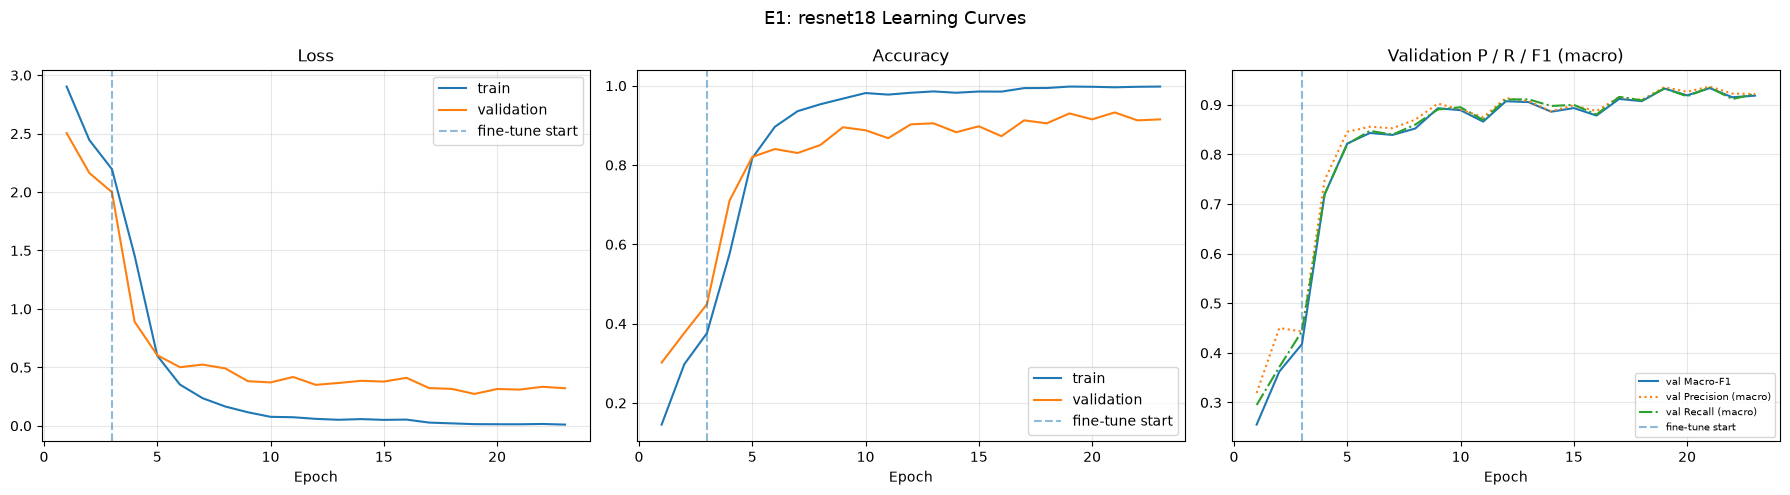

In [21]:
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_history.csv", index=False)
epochs = np.arange(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(epochs, history_df["train_loss"], label="train")
axes[0].plot(epochs, history_df["val_loss"], label="validation")
axes[0].axvline(HEAD_EPOCHS, ls="--", alpha=0.5, label="fine-tune start")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history_df["train_acc"], label="train")
axes[1].plot(epochs, history_df["val_acc"], label="validation")
axes[1].axvline(HEAD_EPOCHS, ls="--", alpha=0.5, label="fine-tune start")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(epochs, history_df["val_f1_macro"], label="val Macro-F1")
axes[2].plot(epochs, history_df["val_precision_macro"], label="val Precision (macro)", ls=":")
axes[2].plot(epochs, history_df["val_recall_macro"], label="val Recall (macro)", ls="-.")
axes[2].axvline(HEAD_EPOCHS, ls="--", alpha=0.5, label="fine-tune start")
axes[2].set_title("Validation P / R / F1 (macro)")
axes[2].set_xlabel("Epoch")
axes[2].legend(fontsize=7)
axes[2].grid(alpha=0.3)

plt.suptitle(f"{EXPERIMENT_ID}: {MODEL_NAME} Learning Curves", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_learning_curves.png", dpi=150)
plt.show()

## 13. Final test evaluation

The best checkpoint (selected on validation Macro-F1) is loaded and evaluated **once** on the test set.

### Teacher-required metrics reported here

| Metric | Averaging |
|---|---|
| Accuracy | — |
| Precision | macro |
| Recall | macro |
| F1-score | macro |

### Additional

| Metric | Purpose |
|---|---|
| Balanced accuracy | Per-class recall average |
| Weighted F1 | Frequency-weighted |
| Top-1 … Top-10 | n-best classification |

### Test-set reminder

This test result is **reported, not used for decisions**. Architecture, augmentation, loss, and epoch choices were all made on the validation set.

In [22]:
checkpoint = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

print(f"Loaded best checkpoint ({EXPERIMENT_ID})")
print("Stage       :", checkpoint["stage"])
print("Epoch       :", checkpoint["epoch"])
print("Val F1 macro:", f"{checkpoint['val_f1_macro']:.4f}")
print("Val accuracy:", f"{checkpoint['val_accuracy']:.4f}")

test_metrics = evaluate(model, test_loader, criterion, DEVICE, USE_AMP)
test_preds = test_metrics["predictions"]
test_labels = test_metrics["labels"]

print("\n" + "=" * 60)
print(f"  {EXPERIMENT_ID} FINAL TEST RESULTS — {MODEL_NAME}")
print("=" * 60)
print(f"  Test loss              : {test_metrics['loss']:.4f}")
print(f"  Test Accuracy          : {test_metrics['accuracy']:.4f}")
print(f"  Test Precision (macro) : {test_metrics['precision_macro']:.4f}")
print(f"  Test Recall (macro)    : {test_metrics['recall_macro']:.4f}")
print(f"  Test F1 (macro)        : {test_metrics['f1_macro']:.4f}")
print(f"  Test Balanced accuracy : {test_metrics['balanced_accuracy']:.4f}")
print(f"  Test F1 (weighted)     : {test_metrics['f1_weighted']:.4f}")
print("=" * 60)

print("\nPer-class classification report:\n")
report = classification_report(
    test_labels, test_preds,
    target_names=class_names, digits=4, zero_division=0,
)
print(report)

with open(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_report.txt", "w") as f:
    f.write(report)

Loaded best checkpoint (E1)
Stage       : finetune
Epoch       : 18
Val F1 macro: 0.9336
Val accuracy: 0.9327

  E1 FINAL TEST RESULTS — resnet18
  Test loss              : 0.6351
  Test Accuracy          : 0.8321
  Test Precision (macro) : 0.8819
  Test Recall (macro)    : 0.8484
  Test F1 (macro)        : 0.8449
  Test Balanced accuracy : 0.8484
  Test F1 (weighted)     : 0.8318

Per-class classification report:

                                   precision    recall  f1-score   support

                    Acer palmatum     0.9474    0.9474    0.9474        19
                   Cedrus deodara     1.0000    1.0000    1.0000        13
                  Celtis sinensis     1.0000    0.5217    0.6857        23
 Cinnamomum camphora (Linn) Presl     1.0000    0.8095    0.8947        21
            Elaeocarpus decipiens     0.8696    1.0000    0.9302        20
                 Flowering cherry     1.0000    0.6923    0.8182        13
                    Ginkgo biloba     1.0000    0.5385 

## 14. n-best (Top-k) classification

**Project requirement:** *"Calculate the n-best classification results. Find the value n beyond which the n-best results start to separate the model performance between the models."*

This section computes Top-k accuracy for k = 1…10 and saves the results as JSON.

**In E2**, the ResNet-50 Top-k results will be loaded and plotted alongside these ResNet-18 results. The separation point `n` will be identified from that cross-model plot.

```text
E1 saves: resnet18_E1_topk.json   (in ./outputs/dan/training_baseline/)
E2 saves: resnet50_E2_topk.json   (in ./outputs/dan/training_architecture/)
E2 loads both → overlay plot → identify separation point n
```


E1 — resnet18 — Top-k Test Accuracy
----------------------------------------
  Top- 1: 0.8321
  Top- 2: 0.9136
  Top- 3: 0.9358
  Top- 4: 0.9457
  Top- 5: 0.9531
  Top- 6: 0.9556
  Top- 7: 0.9580
  Top- 8: 0.9605
  Top- 9: 0.9630
  Top-10: 0.9704

Saved to: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training_baseline/resnet18_E1_topk.json


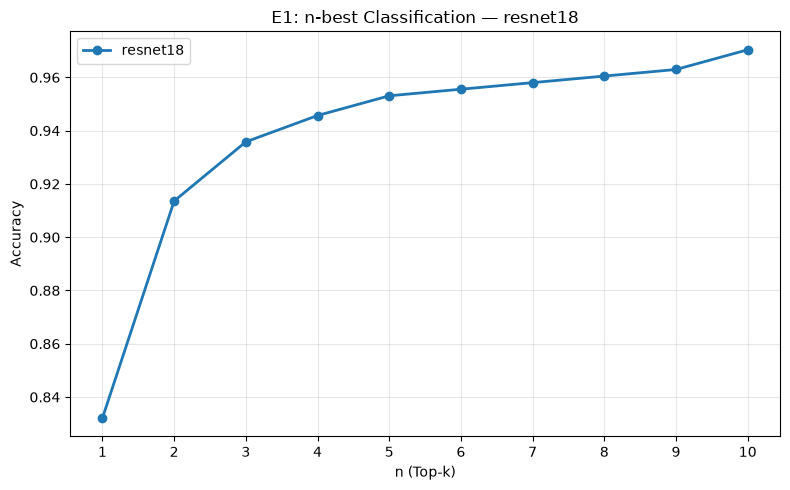


Note: The cross-model separation plot (ResNet-18 vs ResNet-50)
will be produced in E2 after ResNet-50 is trained.


In [23]:
k_values = list(range(1, 11))
top_k_correct = {k: 0 for k in k_values}
total_test = 0

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if USE_AMP:
            with torch.autocast(device_type="cuda"):
                outputs = model(images)
        else:
            outputs = model(images)

        max_k = max(k_values)
        top_k_preds = outputs.topk(k=max_k, dim=1).indices
        total_test += labels.size(0)

        for k in k_values:
            correct = (top_k_preds[:, :k] == labels.unsqueeze(1)).any(dim=1).sum().item()
            top_k_correct[k] += correct

top_k_acc = {k: top_k_correct[k] / total_test for k in k_values}

print(f"\n{EXPERIMENT_ID} — {MODEL_NAME} — Top-k Test Accuracy")
print("-" * 40)
for k in k_values:
    print(f"  Top-{k:2d}: {top_k_acc[k]:.4f}")

# Save for E2 cross-model comparison
topk_payload = {
    "experiment": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "k_values": k_values,
    "top_k_accuracy": {str(k): top_k_acc[k] for k in k_values},
}
with open(TOPK_PATH, "w") as f:
    json.dump(topk_payload, f, indent=2)

print(f"\nSaved to: {TOPK_PATH}")

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, [top_k_acc[k] for k in k_values], marker="o", linewidth=2, label=MODEL_NAME)
ax.set_xticks(k_values)
ax.set_xlabel("n (Top-k)")
ax.set_ylabel("Accuracy")
ax.set_title(f"{EXPERIMENT_ID}: n-best Classification — {MODEL_NAME}")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_topk.png", dpi=150)
plt.show()

print("\nNote: The cross-model separation plot (ResNet-18 vs ResNet-50)")
print("will be produced in E2 after ResNet-50 is trained.")

## 15. Confusion matrix

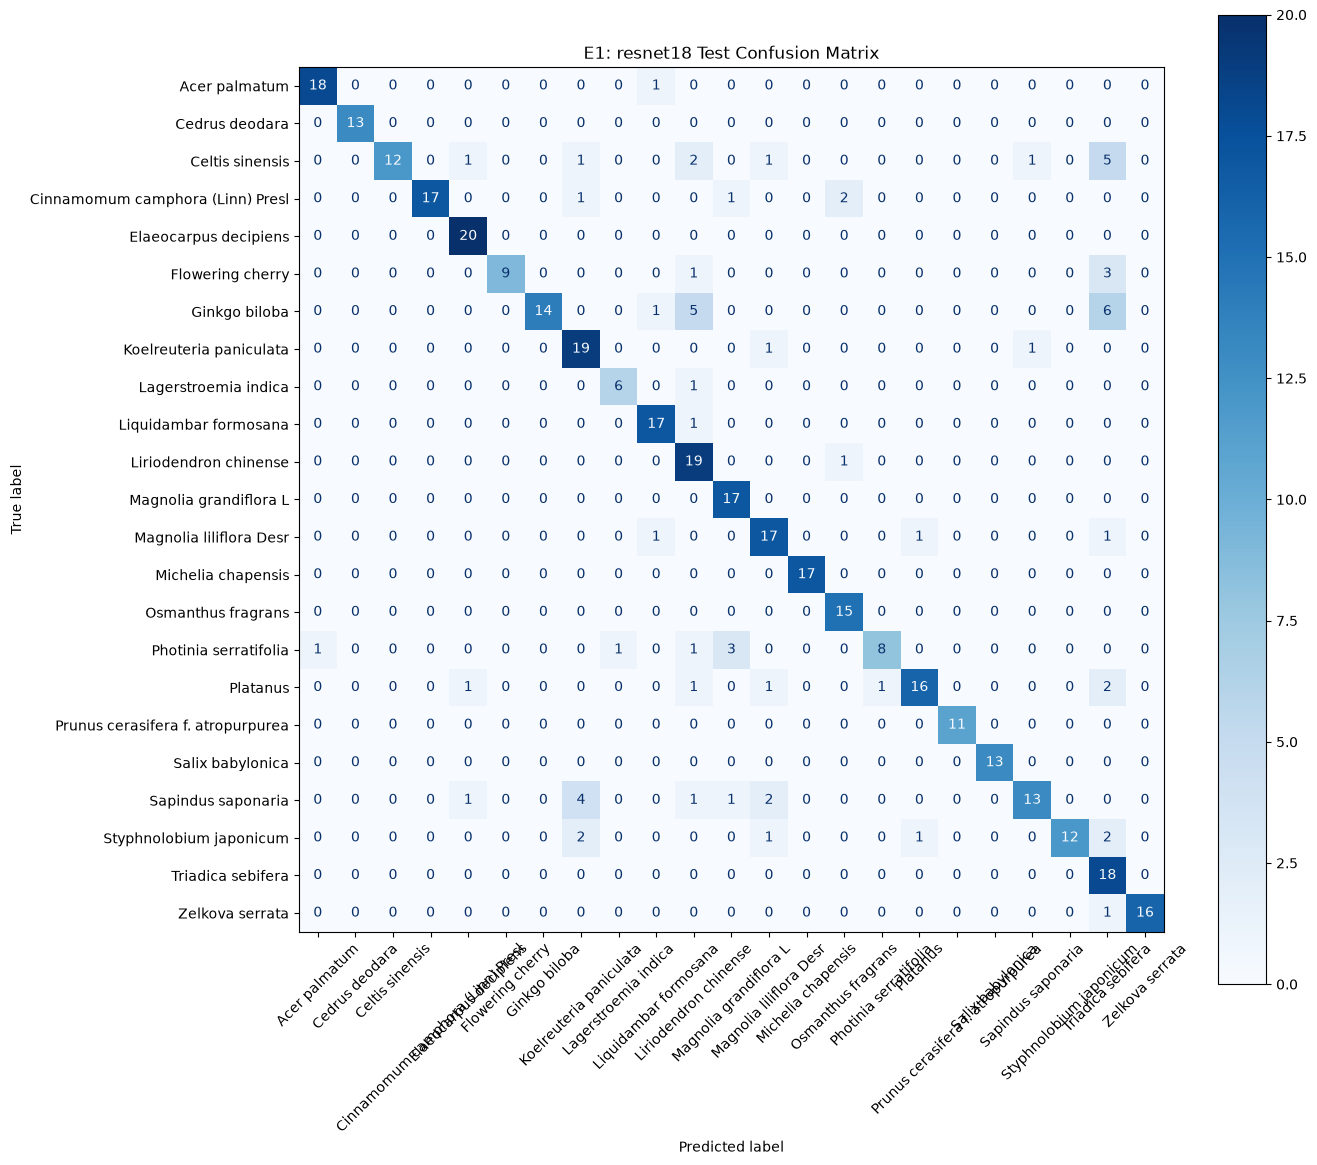

Confusion matrix saved.


In [24]:
cm = confusion_matrix(test_labels, test_preds)

fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, values_format="d", cmap="Blues")
plt.title(f"{EXPERIMENT_ID}: {MODEL_NAME} Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_confusion_matrix.png", dpi=150)
plt.show()

pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_confusion_matrix.csv"
)
print("Confusion matrix saved.")

## 16. Per-class performance

In [25]:
report_dict = classification_report(
    test_labels, test_preds,
    target_names=class_names, output_dict=True, zero_division=0,
)
per_class_df = pd.DataFrame(report_dict).T
per_class_df = per_class_df.loc[
    [n for n in class_names if n in per_class_df.index],
    ["precision", "recall", "f1-score", "support"],
]
per_class_df = per_class_df.sort_values("f1-score")

print(f"{EXPERIMENT_ID}: {MODEL_NAME} — Per-class metrics (sorted by F1)\n")
display(per_class_df)

per_class_df.to_csv(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_per_class.csv")

E1: resnet18 — Per-class metrics (sorted by F1)



,precision,recall,f1-score,support
Triadica sebifera,0.473684,1.000000,0.642857,18.0
Celtis sinensis,1.000000,0.521739,0.685714,23.0
Photinia serratifolia,0.888889,0.571429,0.695652,14.0
Ginkgo biloba,1.000000,0.538462,0.700000,26.0
Sapindus saponaria,0.866667,0.590909,0.702703,22.0
Liriodendron chinense,0.593750,0.950000,0.730769,20.0
Magnolia liliflora Desr,0.739130,0.850000,0.790698,20.0
Koelreuteria paniculata,0.703704,0.904762,0.791667,21.0
Platanus,0.888889,0.727273,0.800000,22.0
Styphnolobium japonicum,1.000000,0.666667,0.800000,18.0


## 17. Error analysis → input for E3

### Important distinction

This section is **analysis, not improvement**. It identifies failure patterns that will motivate the actual improvement experiment in E3.

```text
E1 error analysis (this section)
        ↓
Identify repeated failure patterns
        ↓
E3: implement ONE evidence-driven improvement
        ↓
Compare E1 vs E3 on validation
        ↓
If improvement confirmed → freeze → test once
```

### What to look for

1. **Visually similar species** consistently confused
2. **Poor image quality** (blur, lighting, background)
3. **Missing botanical features** (only trunk, no leaves)
4. **Class imbalance** causing poor minority-class recall
5. **Possible annotation errors**

### Grading connection

The 20% "Improving your model" grade requires:
- documenting repeated errors (this section)
- proposing a specific solution
- **actually executing** the improvement in E3
- comparing E1 vs E3 quantitatively

Misclassified: 68 of 405 test images

Top 10 confusion pairs (true → predicted):
(Ginkgo biloba, Triadica sebifera)                        6
(Celtis sinensis, Triadica sebifera)                      5
(Ginkgo biloba, Liriodendron chinense)                    5
(Sapindus saponaria, Koelreuteria paniculata)             4
(Flowering cherry, Triadica sebifera)                     3
(Photinia serratifolia, Magnolia grandiflora L)           3
(Celtis sinensis, Liriodendron chinense)                  2
(Cinnamomum camphora (Linn) Presl, Osmanthus fragrans)    2
(Platanus, Triadica sebifera)                             2
(Sapindus saponaria, Magnolia liliflora Desr)             2


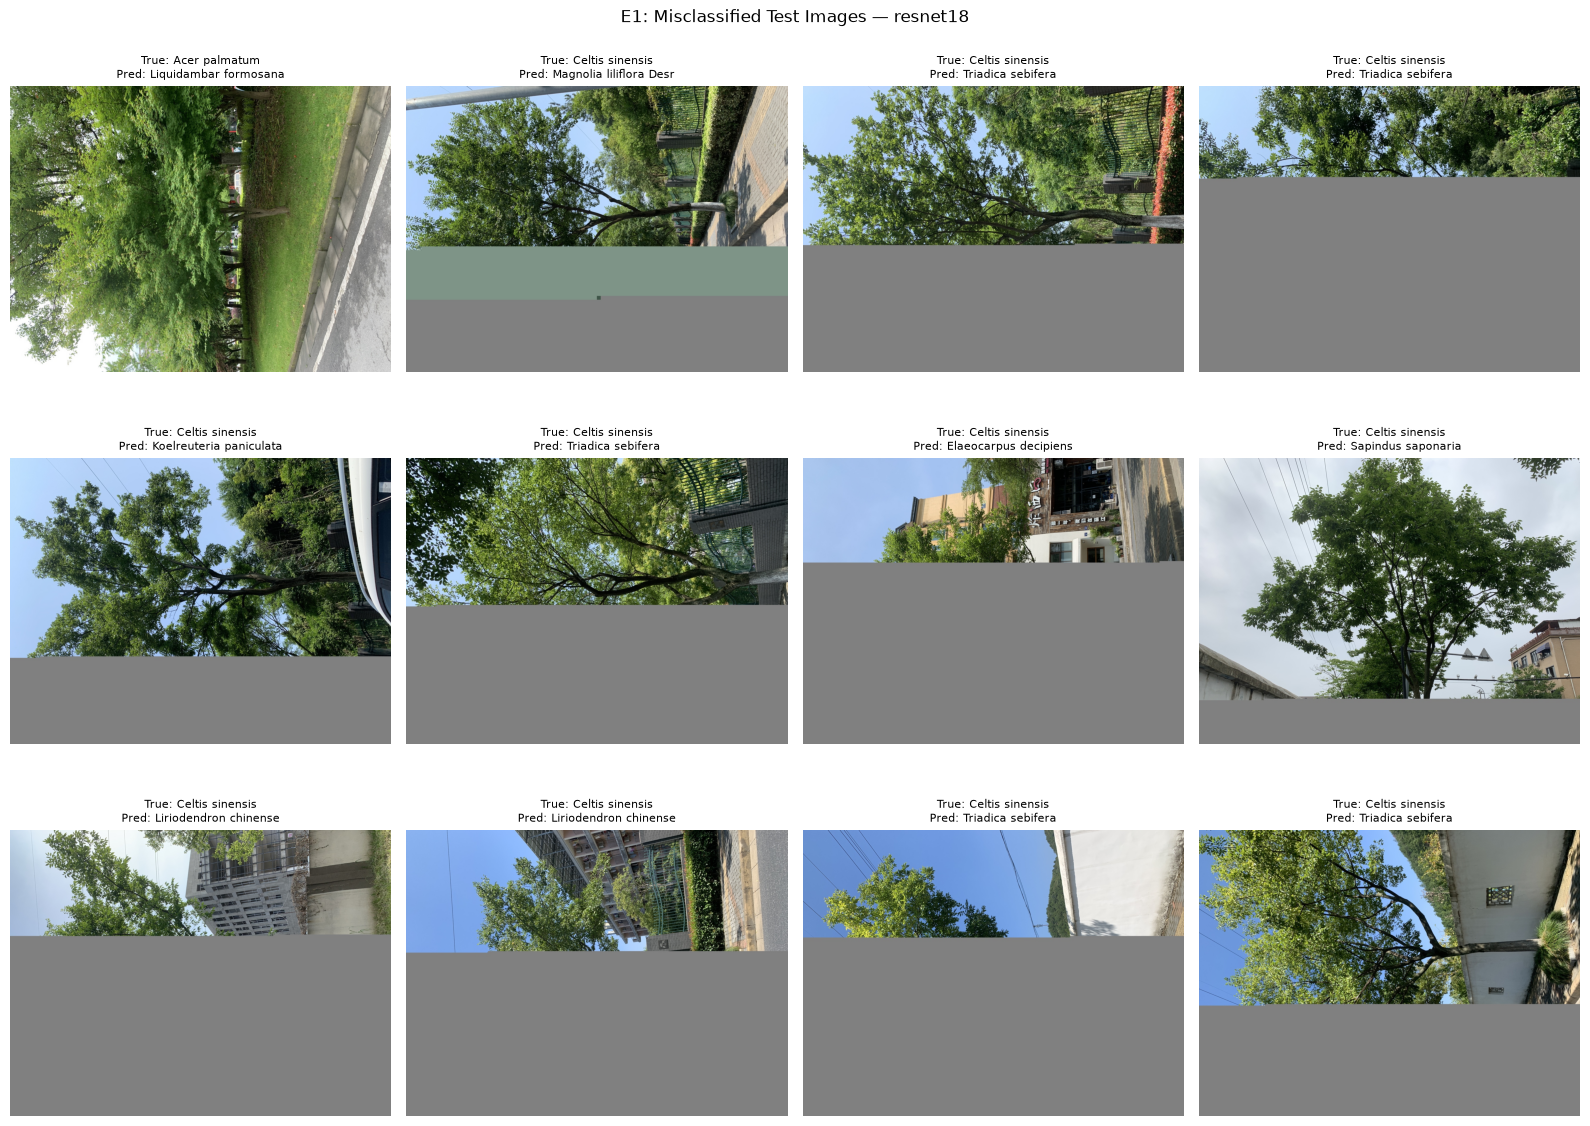

In [26]:
misclassified_idx = np.where(test_preds != test_labels)[0]
print(f"Misclassified: {len(misclassified_idx)} of {len(test_labels)} test images")

# Most common confusion pairs
confusion_pairs = []
for idx in misclassified_idx:
    true_cls = class_names[test_labels[idx]]
    pred_cls = class_names[test_preds[idx]]
    confusion_pairs.append((true_cls, pred_cls))

if confusion_pairs:
    pair_counts = pd.Series(confusion_pairs).value_counts().head(10)
    print("\nTop 10 confusion pairs (true → predicted):")
    print(pair_counts.to_string())

# Visualize misclassified examples
n_show = min(12, len(misclassified_idx))
if n_show > 0:
    n_cols = 4
    n_rows = int(np.ceil(n_show / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, misclassified_idx[:n_show]):
        path, true_label = test_dataset.samples[idx]
        pred_label = int(test_preds[idx])
        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(
                f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}",
                fontsize=8,
            )
        except Exception:
            ax.set_title("Could not load")
        ax.axis("off")
    plt.suptitle(f"{EXPERIMENT_ID}: Misclassified Test Images — {MODEL_NAME}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_errors.png", dpi=150)
    plt.show()

## 18. Save experiment configuration and results registry

In [27]:
# Configuration
config = {
    "experiment_id": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "pretrained": "ImageNet",
    "num_classes": EXPECTED_NUM_CLASSES,
    "train_images": len(train_dataset),
    "val_images": len(val_dataset),
    "test_images": len(test_dataset),
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "head_epochs": HEAD_EPOCHS,
    "finetune_epochs": FINETUNE_EPOCHS,
    "head_lr": HEAD_LR,
    "backbone_lr": BACKBONE_LR,
    "weight_decay": WEIGHT_DECAY,
    "loss": "CrossEntropyLoss",
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau",
    "primary_metric": "val_f1_macro",
    "use_amp": USE_AMP,
    "test_accuracy": float(test_metrics["accuracy"]),
    "test_precision_macro": float(test_metrics["precision_macro"]),
    "test_recall_macro": float(test_metrics["recall_macro"]),
    "test_f1_macro": float(test_metrics["f1_macro"]),
    "test_balanced_accuracy": float(test_metrics["balanced_accuracy"]),
    "test_f1_weighted": float(test_metrics["f1_weighted"]),
}
with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)
print("Config saved:", CONFIG_PATH)

# Results registry
result_row = {
    "experiment": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "augmentation": "baseline_mild",
    "loss": "CrossEntropyLoss",
    "optimizer": "AdamW",
    "val_f1_macro": float(checkpoint["val_f1_macro"]),
    "val_accuracy": float(checkpoint["val_accuracy"]),
    "val_precision_macro": float(checkpoint["val_precision_macro"]),
    "val_recall_macro": float(checkpoint["val_recall_macro"]),
    "test_accuracy": float(test_metrics["accuracy"]),
    "test_precision_macro": float(test_metrics["precision_macro"]),
    "test_recall_macro": float(test_metrics["recall_macro"]),
    "test_f1_macro": float(test_metrics["f1_macro"]),
    "test_balanced_accuracy": float(test_metrics["balanced_accuracy"]),
}

if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
    results_df = results_df[results_df["experiment"] != EXPERIMENT_ID]
    results_df = pd.concat([results_df, pd.DataFrame([result_row])], ignore_index=True)
else:
    results_df = pd.DataFrame([result_row])

results_df.to_csv(RESULTS_PATH, index=False)
print("Results registry:", RESULTS_PATH)
display(results_df)

Config saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training_baseline/resnet18_E1_config.json
Results registry: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/experiment_results.csv


,experiment,model,augmentation,loss,optimizer,val_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_balanced_accuracy
0,E1,resnet18,baseline_mild,CrossEntropyLoss,AdamW,0.933604,0.932668,0.936661,0.934735,0.832099,0.88195,0.8484,0.844915,0.8484
